CS3920/CS5920-202526

In [1]:
import matplotlib.lines as plt
from sklearn.datasets import load_diabetes
diabetes = load_diabetes()
diabetes.data.shape

(442, 10)

In [2]:
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

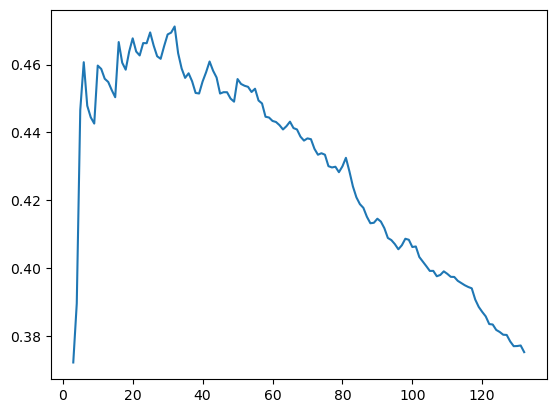

In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(diabetes['data'], diabetes['target'], random_state = 42)

from sklearn.neighbors import KNeighborsRegressor
K_max = 130
import numpy as np
results = np.empty(K_max)

for k in range(K_max):
    knn = KNeighborsRegressor(n_neighbors = k+3)
    knn.fit(X_train, y_train)
    results[k] = knn.score(X_test, y_test)

%matplotlib inline
import matplotlib.pyplot as plt
plt.plot(np.arange(K_max) + 3, results)
plt.show()

In [4]:
help(KNeighborsRegressor.score)

Help on function score in module sklearn.base:

score(self, X, y, sample_weight=None)
    Return the coefficient of determination of the prediction.

    The coefficient of determination :math:`R^2` is defined as
    :math:`(1 - \frac{u}{v})`, where :math:`u` is the residual
    sum of squares ``((y_true - y_pred)** 2).sum()`` and :math:`v`
    is the total sum of squares ``((y_true - y_true.mean()) ** 2).sum()``.
    The best possible score is 1.0 and it can be negative (because the
    model can be arbitrarily worse). A constant model that always predicts
    the expected value of `y`, disregarding the input features, would get
    a :math:`R^2` score of 0.0.

    Parameters
    ----------
    X : array-like of shape (n_samples, n_features)
        Test samples. For some estimators this may be a precomputed
        kernel matrix or a list of generic objects instead with shape
        ``(n_samples, n_samples_fitted)``, where ``n_samples_fitted``
        is the number of samples used i

In [5]:
from sklearn.model_selection import cross_val_score
knn= KNeighborsRegressor(n_neighbors = 3)
cross_val_score(knn, X_train, y_train)

array([0.28743721, 0.24283699, 0.32312734, 0.32108514, 0.12845082])

In [6]:
from sklearn.utils import shuffle
X, y = shuffle(diabetes.data, diabetes.target, random_state = 42)
print(cross_val_score(knn, X, y))

[0.36498737 0.32300369 0.26748019 0.43230668 0.40572547]


In [7]:
knn.fit(X_train, y_train)
knn.score(X_test, y_test)

0.37222167132521977

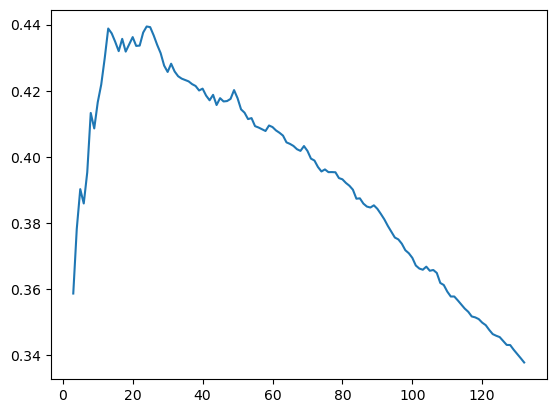

In [8]:
K_max = 130
for k in range(K_max):
    knn = KNeighborsRegressor(n_neighbors = k+3)
    results[k] = np.mean(cross_val_score(knn, X, y))
plt.plot(np.arange(K_max) + 3, results)
plt.show()

### Exercise 1

The role of 'np.mean' is to take all the elements of an array, add them up and divide them by the length of the array which is the mean of the array.

### Exercise 2


I tested a wider range of \(K\) values from 3 to 120 for both the single train–test split (as in In[3]) and the cross-validation setup (as in In[8]).

Optimal \(K\) values:

- Single train–test split (In[3]):
  - Optimal \(K = 32\)
  - Best \(R^2 \approx 0.471\)

- Cross-validation (In[8]):
  - Optimal \(K = 18\)
  - Best \(R^2 \approx 0.444\)

Comparison of inverted U-shaped curves:

- Both methods show a clear inverted U pattern: performance improves as \(K\) increases initially, peaks, then declines as \(K\) becomes large.
- The cross-validation curve peaks earlier and slightly lower since it averages across folds and avoids lucky splits.
- For large \(K\) values (towards 120), both curves decline notably. With many neighbours the model becomes overly smooth and predictions move toward the global mean, increasing bias and reducing performance.
- The single-split curve stays slightly higher at large \(K\), but this is due to variance from one random split.

Conclusion:

Cross-validation gives a more reliable estimate and suggests the optimal choice is \(K \approx 18\). The single-split optimum at \(K \approx 32\) is less reliable and likely optimistic.

{'single_split_opt_k': 32, 'single_split_opt_R2': 0.4712, 'cv_opt_k': 18, 'cv_opt_R2': 0.4439}


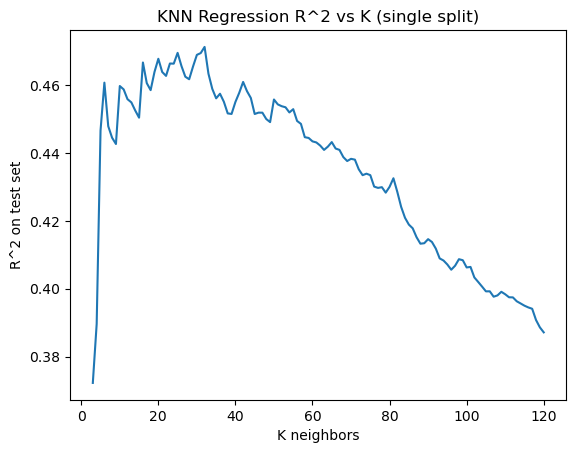

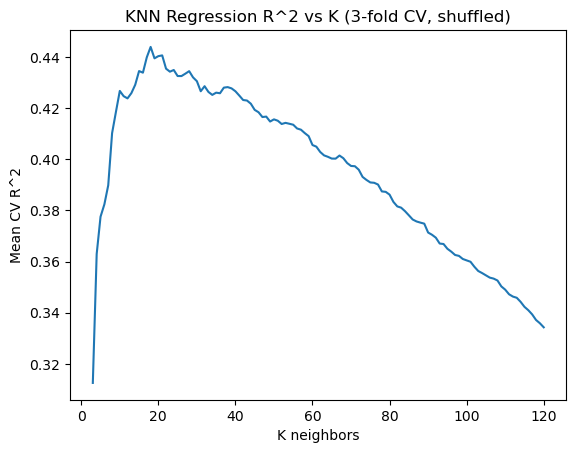

In [9]:
# Exercise 2: Sweep K across wider ranges for In[3] and In[8], report optimal K, and compare curves.

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.utils import shuffle

# Load dataset
diabetes = load_diabetes()
X_full, y_full = diabetes.data, diabetes.target

# === In[3]-style: single train/test split ===
X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, random_state=42
)

def sweep_k_single_split(k_min=3, k_max=120):
    ks = np.arange(k_min, k_max + 1)
    scores = np.empty_like(ks, dtype=float)
    for i, k in enumerate(ks):
        knn = KNeighborsRegressor(n_neighbors=int(k))
        knn.fit(X_train, y_train)
        scores[i] = knn.score(X_test, y_test)
    return ks, scores

# === In[8]-style: cross-validation on shuffled data ===
X_cv, y_cv = shuffle(X_full, y_full, random_state=42)

def sweep_k_cv(k_min=3, k_max=120, cv=3):
    ks = np.arange(k_min, k_max + 1)
    scores = np.empty_like(ks, dtype=float)
    for i, k in enumerate(ks):
        knn = KNeighborsRegressor(n_neighbors=int(k))
        cv_scores = cross_val_score(knn, X_cv, y_cv, cv=cv)
        scores[i] = np.mean(cv_scores)
    return ks, scores

# Run sweeps
ks_split, scores_split = sweep_k_single_split(3, 120)
ks_cv, scores_cv = sweep_k_cv(3, 120, cv=3)

# Identify optima
opt_idx_split = int(np.argmax(scores_split))
opt_k_split = int(ks_split[opt_idx_split])
opt_score_split = float(scores_split[opt_idx_split])

opt_idx_cv = int(np.argmax(scores_cv))
opt_k_cv = int(ks_cv[opt_idx_cv])
opt_score_cv = float(scores_cv[opt_idx_cv])

print({
    "single_split_opt_k": opt_k_split,
    "single_split_opt_R2": round(opt_score_split, 4),
    "cv_opt_k": opt_k_cv,
    "cv_opt_R2": round(opt_score_cv, 4)
})

# Plot 1: single split curve
plt.figure()
plt.plot(ks_split, scores_split)
plt.title("KNN Regression R^2 vs K (single split)")
plt.xlabel("K neighbors")
plt.ylabel("R^2 on test set")
plt.show()

# Plot 2: cross-validation curve
plt.figure()
plt.plot(ks_cv, scores_cv)
plt.title("KNN Regression R^2 vs K (3-fold CV, shuffled)")
plt.xlabel("K neighbors")
plt.ylabel("Mean CV R^2")
plt.show()

### Exercise 3
As the values for K increases the performance increases also at the start but then levels off once it reaches the higher K values.

### Exercise 4
If you only set train_size, the test set automatically becomes the remaining portion of the data. If you only set test_size, the training set becomes the remainder. Yes, scikit-learn allows specifying both.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_diabetes
import numpy as np

data = load_diabetes().data
N = len(data)

# Case 1: only train_size
X_train_1, X_test_1 = train_test_split(data, train_size=0.7, random_state=42)
print("Only train_size set:")
print("train size =", len(X_train_1))
print("test size  =", len(X_test_1))
print()

# Case 2: only test_size
X_train_2, X_test_2 = train_test_split(data, test_size=0.3, random_state=42)
print("Only test_size set:")
print("train size =", len(X_train_2))
print("test size  =", len(X_test_2))
print()

# Case 3: both train_size and test_size
X_train_3, X_test_3 = train_test_split(data, train_size=0.6, test_size=0.2, random_state=42)
print("Both train_size and test_size set:")
print("train size =", len(X_train_3))
print("test size  =", len(X_test_3))
print("unused samples (due to both params) =", N - len(X_train_3) - len(X_test_3))

Only train_size set:
train size = 309
test size  = 133

Only test_size set:
train size = 309
test size  = 133

Both train_size and test_size set:
train size = 265
test size  = 89
unused samples (due to both params) = 88


### Exercise 5
'np.cumsum' computes the cumulative sum of array elements. So In[16] is plotting a cumulative frequency graph.

### Exercise 6

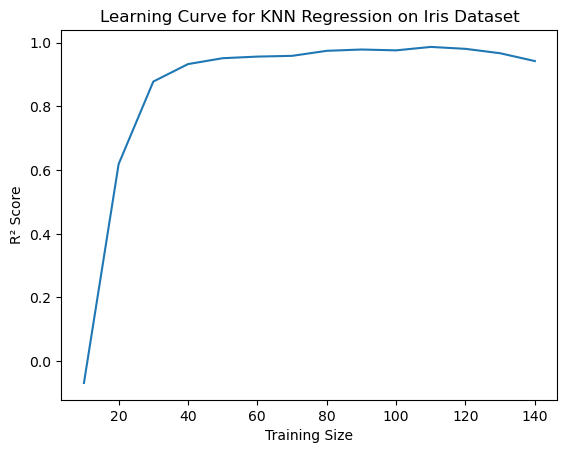

In [11]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
import numpy as np
import matplotlib.pyplot as plt

iris = load_iris()
knn = KNeighborsRegressor(n_neighbors=10)

train_sizes = np.array([10,20,30,40,50,60,70,80,90,100,110,120,130,140])
results = np.empty(train_sizes.size)

for k in range(train_sizes.size):
    X_train, X_test, y_train, y_test = train_test_split(
        iris.data, iris.target, train_size=train_sizes[k], random_state=42
    )
    knn.fit(X_train, y_train)
    results[k] = knn.score(X_test, y_test)

plt.plot(train_sizes, results)
plt.xlabel("Training Size")
plt.ylabel("R² Score")
plt.title("Learning Curve for KNN Regression on Iris Dataset")
plt.show()